In [22]:
from pathlib import Path
import sys

# On remonte jusqu'à la racine du projet
PROJECT_ROOT = Path().resolve()
while not (PROJECT_ROOT / "src").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent

# On ajoute la racine au PATH Python
sys.path.append(str(PROJECT_ROOT))

PROJECT_ROOT


WindowsPath('C:/Users/canpe/Documents/classicmodels-analysis')

# Market Basket Analysis (Analyse de panier)

## Objectif
Identifier les produits fréquemment achetés ensemble afin de comprendre les comportements
d’achat et de proposer des recommandations pertinentes.

## Intérêt métier
L’analyse de panier permet :
- d’optimiser le cross-selling et l’up-selling,
- de concevoir des bundles produits,
- d’améliorer la mise en avant des produits (merchandising),
- d’augmenter le panier moyen.

## Justification de la méthode
Les règles d’association (Apriori) mettent en évidence des relations fréquentes entre produits
au sein des mêmes commandes. Cette approche est adaptée aux données transactionnelles
et fournit des règles simples et interprétables.

In [23]:
from pathlib import Path
import sys

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Détection de la racine du projet
PROJECT_ROOT = None
for p in Path().resolve().parents:
    if (p / "requirements.txt").exists() and (p / "src").exists() and (p / "visualizations").exists():
        PROJECT_ROOT = p
        break

if PROJECT_ROOT is None:
    raise RuntimeError("Racine du projet introuvable.")

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

OUTPUT_DIR = PROJECT_ROOT / "visualizations" / "part4"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

PROJECT_ROOT, OUTPUT_DIR

(WindowsPath('C:/Users/canpe/Documents/classicmodels-analysis'),
 WindowsPath('C:/Users/canpe/Documents/classicmodels-analysis/visualizations/part4'))

In [24]:
# Suppression des warnings non bloquants pour améliorer la lisibilité du notebook
import warnings
warnings.filterwarnings("ignore", category=UserWarning)

In [25]:
from src.analysis.db import get_connection
def fetch_df(query, params=None):
    conn = get_connection()
    df = pd.read_sql(query, conn, params=params)
    conn.close()
    return df

In [26]:
sql = """
SELECT
    od.orderNumber,
    od.productCode,
    p.productName
FROM orderdetails od
JOIN products p ON od.productCode = p.productCode
ORDER BY od.orderNumber;
"""
basket = fetch_df(sql)
basket.head(), basket.shape


(   orderNumber productCode                          productName
 0        10100    S18_1749             1917 Grand Touring Sedan
 1        10100    S18_2248                   1911 Ford Town Car
 2        10100    S18_4409  1932 Alfa Romeo 8C2300 Spider Sport
 3        10100    S24_3969     1936 Mercedes Benz 500k Roadster
 4        10101    S18_2325            1932 Model A Ford J-Coupe,
 (2996, 3))

In [27]:
basket_matrix = (
    basket
    .assign(value=1)
    .pivot_table(
        index="orderNumber",
        columns="productName",
        values="value",
        fill_value=0
    )
)

basket_matrix.head()


productName,18th Century Vintage Horse Carriage,18th century schooner,1900s Vintage Bi-Plane,1900s Vintage Tri-Plane,1903 Ford Model A,1904 Buick Runabout,1911 Ford Town Car,1912 Ford Model T Delivery Wagon,1913 Ford Model T Speedster,1917 Grand Touring Sedan,...,Diamond T620 Semi-Skirted Tanker,F/A 18 Hornet 1/72,HMS Bounty,P-51-D Mustang,Pont Yacht,The Mayflower,The Queen Mary,The Schooner Bluenose,The Titanic,The USS Constitution Ship
orderNumber,,,,,,,,,,,,,,,,,,,,,
10100,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
10101,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
10102,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
10103,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
10104,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


LA matrice binaire est naturellement creuse car chaque commande contient un nombre petit de produits par rapport au catalogue totale. Cette structure est normale et définie les données transactionnelles et est adaptée a l'algo Apriori.

In [28]:
from mlxtend.frequent_patterns import apriori, association_rules

frequent_itemsets = apriori(
    basket_matrix,
    min_support=0.02,   # seuil raisonnable pour ClassicModels
    use_colnames=True
)

rules = association_rules(
    frequent_itemsets,
    metric="lift",
    min_threshold=1.0
)

rules.sort_values("lift", ascending=False).head()

c:\Users\canpe\Documents\classicmodels-analysis\.venv\Lib\site-packages\mlxtend\frequent_patterns\fpcommon.py:175: DeprecationWarning: DataFrames with non-bool types result in worse computationalperformance and their support might be discontinued in the future.Please use a DataFrame with bool type
  warnings.warn(


,antecedents,consequents,antecedent support,consequent support,support,confidence,lift,representativity,leverage,conviction,zhangs_metric,jaccard,certainty,kulczynski
2372824,"frozenset({American Airlines: MD-11S, 1941 Che...","frozenset({America West Airlines B757-200, 193...",0.021472,0.021472,0.021472,1.0,46.571429,1.0,0.021011,inf,1.0,1.0,1.0,1.0
1684639,frozenset({1941 Chevrolet Special Deluxe Cabri...,"frozenset({1937 Horch 930V Limousine, 1930 Bui...",0.021472,0.021472,0.021472,1.0,46.571429,1.0,0.021011,inf,1.0,1.0,1.0,1.0
968664,"frozenset({HMS Bounty, 1937 Horch 930V Limousi...","frozenset({America West Airlines B757-200, 194...",0.021472,0.021472,0.021472,1.0,46.571429,1.0,0.021011,inf,1.0,1.0,1.0,1.0
2375650,"frozenset({1930 Buick Marquette Phaeton, HMS B...","frozenset({America West Airlines B757-200, Ame...",0.021472,0.021472,0.021472,1.0,46.571429,1.0,0.021011,inf,1.0,1.0,1.0,1.0
970092,"frozenset({Corsair F4U ( Bird Cage), 1941 Chev...","frozenset({HMS Bounty, 1900s Vintage Bi-Plane,...",0.021472,0.021472,0.021472,1.0,46.571429,1.0,0.021011,inf,1.0,1.0,1.0,1.0


Cette analyse de panier repose sur l’algorithme Apriori afin d’identifier des associations fréquentes entre produits achetés ensemble.
Un seuil de support adapté a été choisi pour limiter la complexité de calcul tout en conservant des règles pertinentes.

Les règles sont classées selon le lift, permettant de mettre en évidence des relations d’achat non aléatoires.
Ces résultats peuvent être exploités pour des stratégies de cross-selling et d’optimisation des offres commerciales.

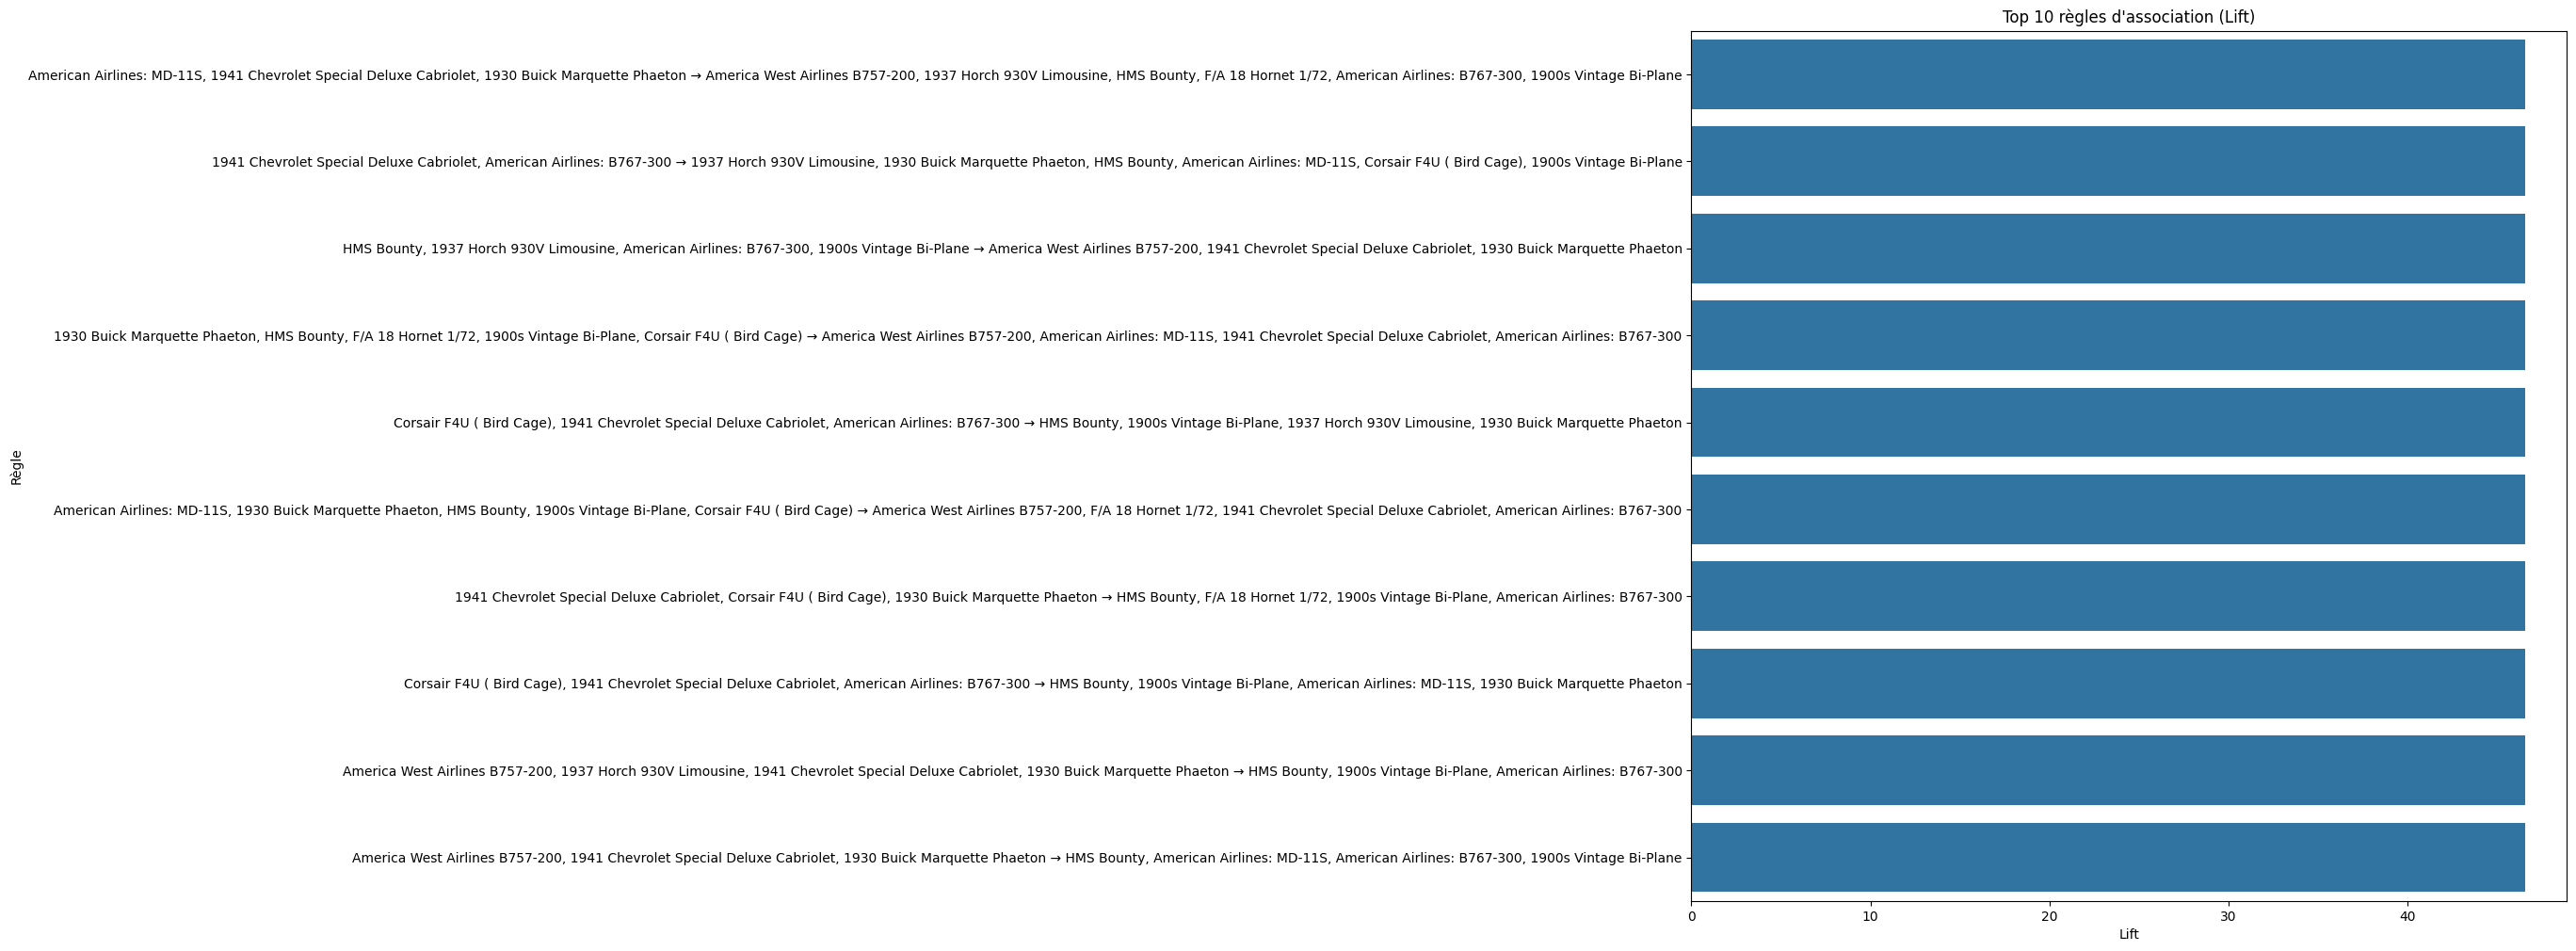

In [33]:
top_rules = rules.sort_values("lift", ascending=False).head(10)

top_rules["antecedents_str"] = top_rules["antecedents"].apply(lambda x: ", ".join(x))
top_rules["consequents_str"] = top_rules["consequents"].apply(lambda x: ", ".join(x))

plt.figure(figsize=(12,12))
sns.barplot(
    data=top_rules,
    x="lift",
    y=top_rules["antecedents_str"] + " → " + top_rules["consequents_str"]
)

plt.title("Top 10 règles d'association (Lift)")
plt.xlabel("Lift")
plt.ylabel("Règle")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "04_market_basket_rules.png", dpi=300, bbox_inches="tight")
plt.show()

## Interprétation

Les règles d’association mettent en évidence des produits fréquemment achetés ensemble,
indiquant des comportements d’achat complémentaires.

Ces relations peuvent être exploitées pour :
- proposer des recommandations automatiques,
- créer des bundles de produits,
- améliorer la disposition des produits dans le catalogue.

L’utilisation du lift permet d’identifier des associations réellement pertinentes
au-delà des simples co-occurrences fréquentes.